# Miniprojekt B

## Frekvensanalyse af EKG, EMG og Blodtryk

**Navne:** Jakob og Lucas 

**AU-ID:**  fdfsdf 


### Indhold:
1. sampletid og tidsplot af muskelsignalerne
2. Frekvenstransformation af 630 signaler
3. Energi under og over 200 Hz
4. Zero-padding til ottedobbeltlængde 
5. R-takker, puls og Heart Rate Variability
6. STFT og frekvensindhold i hvert QRS-kompleks
7. Tre blodtrykssignaler med og uden spektral udglatning
8. Bogopgaver og samlet konklusion


ja troede i starten at vi skulle lave en funktion som hed analysatoren som har blot lige gemt den her men nåede ikke i mål synes det lød dumt 

In [1]:
def frekvensanalyse(x, fsample, N=None):
    """
    Beregner et ensidet amplitude- og energispektrum.

    x       : målt signal
    fsample : samplefrekvens i Hz
    N       : FFT-længde. N >= len(x)
    """
    x = np.asarray(x, dtype=float).ravel()
    L = len(x)
    
    # DFT beregnet med FFT-algoritmen
    X = np.fft.rfft(x, n=N)
    f = np.fft.rfftfreq(N, d=1 / fsample)

    # Ensidet amplitudespektrum
    amplitude = np.abs(X) / L

    # Energi pr. frekvens-bin ifølge Parsevals sætning
    Ebin = np.abs(X)**2 / N

    if N % 2 == 0:
        # Fordobl alle punkter undtagen DC og Nyquist
        amplitude[1:-1] *= 2
        Ebin[1:-1] *= 2
    else:
        # Ved ulige N findes intet Nyquist-punkt
        amplitude[1:] *= 2
        Ebin[1:] *= 2

    return {
        "f": f,
        "X": X,
        "amplitude": amplitude,
        "Ebin": Ebin,
        "E_time": np.sum(x**2),
        "E_frequency": np.sum(Ebin),
        "df": fsample / N,
        "L": L,
        "N": N
    }

## 1. sampletid og tidsplot af muskelsignalerne

"Importer de to muskelsignaler fra Brightspace ‘EMG_Healthy’ og
‘EMG_Myopathy’. Bestem sampletiden og dernæst samplefrekvensen - og plot
så de første 630 samples af begge signaler. Beskriv ligheder og forskelle"

EMG-målepunkter pr signal: Healthy: 630 Myopathy: 630
Healthy:  Sampletiden (Ts) = 0.000250 s
Myopathy: Sampletiden (Ts) = 0.000250 s
Healthy: Samplefrekvens (fs) = 4000 Hz
Myopathy: Samplefrekvens (fs) = 4000 Hz


Text(0, 0.5, 'Amplitude')

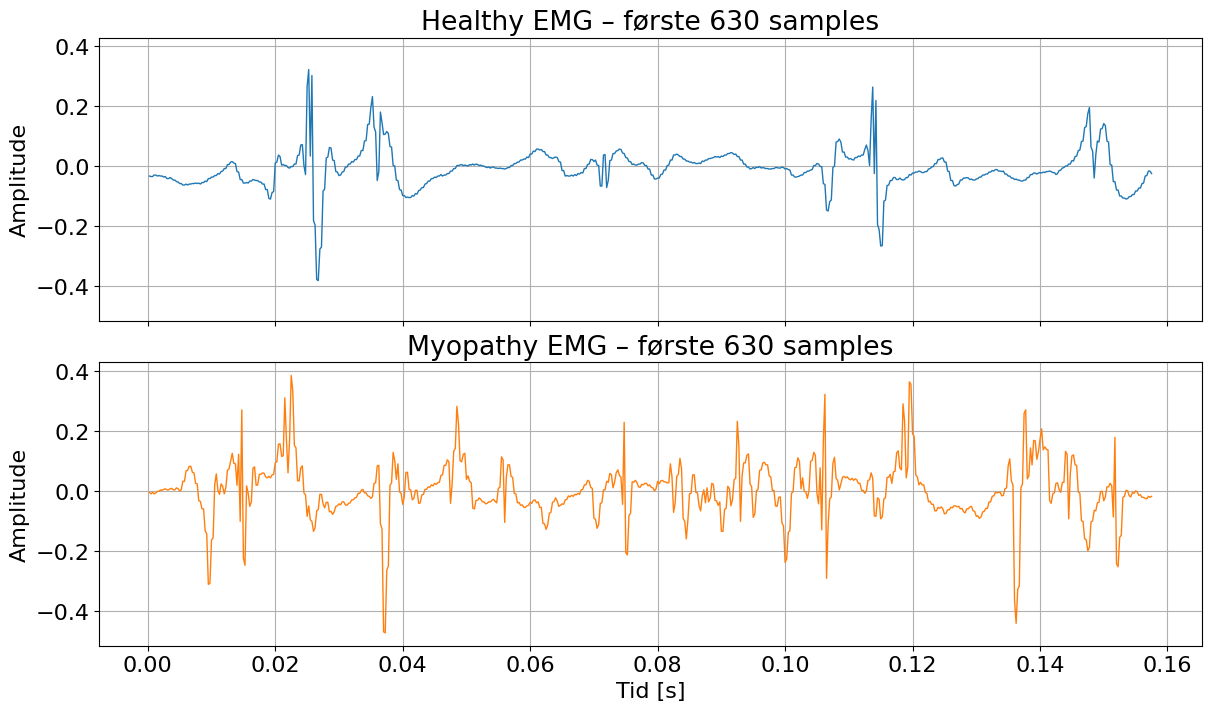

In [2]:
import numpy as np
from scipy import signal
from scipy.io import loadmat
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["font.size"] = 16
plt.rcParams["axes.grid"] = True

healthy = np.loadtxt("EMG_Healthy.txt", max_rows=630)
myopathy = np.loadtxt("EMG_Myopathy.txt", max_rows=630)

# Kolonne 0 = tid, kolonne 1 = EMG signal
t_healthy = healthy[:, 0]
x_healthy = healthy[:, 1]

t_myopathy = myopathy[:, 0]
x_myopathy = myopathy[:, 1]

#målinger pr sekund
dt_healthy = t_healthy[1] - t_healthy[0]
dt_myopathy = t_myopathy[1] - t_myopathy[0]

# Sample frekvens
fs_healthy = 1 / dt_healthy
fs_myopathy = 1 / dt_myopathy

print("EMG-målepunkter pr signal:", "Healthy:", len(x_healthy), "Myopathy:", len(x_myopathy))
print(f"Healthy:  Sampletiden (Ts) = {dt_healthy:.6f} s")
print(f"Myopathy: Sampletiden (Ts) = {dt_myopathy:.6f} s")
print(f"Healthy: Samplefrekvens (fs) = {fs_healthy:.0f} Hz")
print(f"Myopathy: Samplefrekvens (fs) = {fs_myopathy:.0f} Hz")

emg = {"healthy": {
    "t": t_healthy,
    "x": x_healthy,
    "dt": dt_healthy,
    "fs": fs_healthy
}
, "myopathy": {
    "t": t_myopathy,
    "x": x_myopathy,
    "dt": dt_myopathy,
    "fs": fs_myopathy
}
}

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True)

ax[0].plot(t_healthy, x_healthy, linewidth=1)
ax[0].set_title("Healthy EMG – første 630 samples")
ax[0].set_ylabel("Amplitude")

ax[1].plot(t_myopathy, x_myopathy, linewidth=1, color="tab:orange")
ax[1].set_title("Myopathy EMG – første 630 samples")
ax[1].set_xlabel("Tid [s]")
ax[1].set_ylabel("Amplitude")

Sampletiden findes som forskellen mellem to på hinanden følgende
tidspunkter:

Sampletiden beregnes som:

$$
T_s = t_1 - t_0 = 0{,}00025\,\mathrm{s}
$$

Samplefrekvensen bliver derfor:

$$
f_s = \frac{1}{T_s}
= \frac{1}{0{,}00025\,\mathrm{s}}
= 4000\,\mathrm{Hz}
$$

Begge EMG-signaler har dermed samme sampletid og samplefrekvens.
Begge signaler svinger omkring nul og indeholder både positive og
negative, ikke-periodiske udsving.

I de første 630 samples fremstår signalet fra personen med myopati
mere uroligt og indeholder flere hyppige og skarpe udsving. Det raske
signal har generelt længere rolige områder, som afbrydes af enkelte
tydelige aktivitetsudbrud.

## 2. Frekvenstransformation af 630 signaler

Lav frekvenstransformation på de første 630 samples af signalerne i 1), benyt
N=2000 og vis frekvensspektrene. Beskriv igen ligheder og forskelle

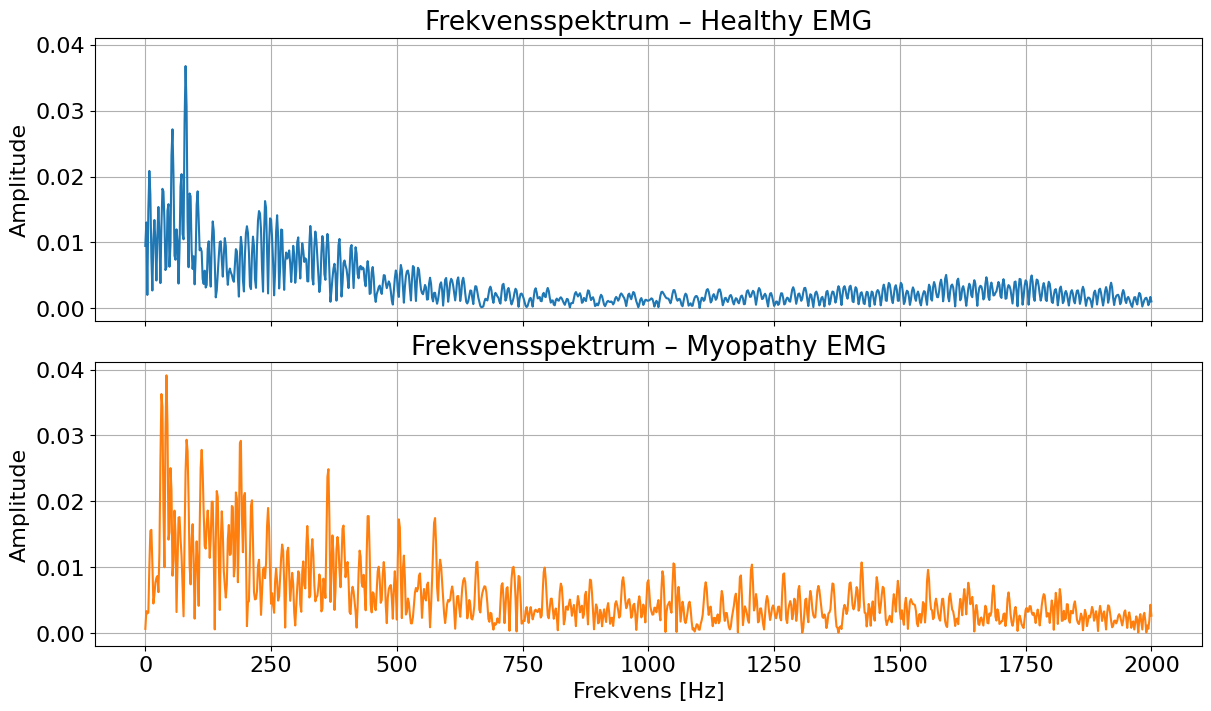

In [ ]:
# FFT-længde
N = 2000
L = 630

def amplitudespektrum(x, fs, N):
    x = np.asarray(x)
    L = len(x)

    # FFT med zero-padding fra 630 til 2000 punkter
    X = np.fft.rfft(x, n=N)

    # Frekvensakse fra 0 til Nyquistfrekvensen
    f = np.fft.rfftfreq(N, d=1/fs)

    # Ensidet amplitudespektrum
    A = np.abs(X) / L
    A[1:-1] *= 2

    return f, A

f_healthy, A_healthy = amplitudespektrum(emg["healthy"]["x"], emg["healthy"]["fs"], N)
f_myopathy, A_myopathy = amplitudespektrum(emg["myopathy"]["x"], emg["myopathy"]["fs"], N)

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

ax[0].plot(f_healthy, A_healthy)
ax[0].set_title("Frekvensspektrum – Healthy EMG")
ax[0].set_ylabel("Amplitude")

ax[1].plot(f_myopathy, A_myopathy, color="tab:orange")
ax[1].set_title("Frekvensspektrum – Myopathy EMG")
ax[1].set_xlabel("Frekvens [Hz]")
ax[1].set_ylabel("Amplitude")

plt.show()

FFT-længde på \(N=2000\). Signalerne er blevet
zero-paddet med 1370 nuller. Frekvensafstanden i det viste spektrum er:

$$
\Delta f = \frac{f_s}{N}
= \frac{4000}{2000}
= 2\,\mathrm{Hz}
$$

begge signaler har hobedsageligt deres største amplituder ved de lavere frekvenser. 

Den største spektrale amplitude findes omkring 80-100 Hz for det raske signal og omkring 40-50 Hz for myopati-signalet. Myopati-signalet har flere fremtrædende toppe fordelt over frekvensaksen, hvilket viser, at dets variationer er fordelt over et bredere frekvensområde. Dette hænger sammen med de hyppigere og skarpere udsving, som ses ovenover i tidsdomænet.

### 3. Energi under og over 200 Hz

"Bestem lavfrekvent energi (under 200Hz) og højfrekvent energi (over 200Hz) for
de to signaler og sammenlign det sunde muskelsignal med det for muskelsvind"

Brug samme segment på 630 samples og samme FFT-længde N=2000. Energien beregnes med Parsevals sætning:
$$
E=\sum_n |x[n]|^2
=\frac{1}{N}\sum_k |X[k]|^2
$$
Her placeres frekvenspunktet præcis ved 200 Hz i det lavfrekvente område:

In [8]:
def beregn_energiområder(x, fs, N=2000, grænse=200):
    x = np.asarray(x)
    
    # DFT med zero-padding
    X = np.fft.rfft(x, n=N)
    f = np.fft.rfftfreq(N, d=1/fs)

    # Energi pr. frekvens-bin
    Ebin = np.abs(X)**2 / N

    # Fordobling ved ensidet spektrum,
    # undtagen DC og Nyquist
    if N % 2 == 0:
        Ebin[1:-1] *= 2
    else:
        Ebin[1:] *= 2

    # 200 Hz medtages i det lavfrekvente område
    E_lav = np.sum(Ebin[f <= grænse])
    E_høj = np.sum(Ebin[f > grænse])
    E_total = E_lav + E_høj

    return {
        "lav": E_lav,
        "høj": E_høj,
        "total": E_total,
        "lav_procent": 100 * E_lav / E_total,
        "høj_procent": 100 * E_høj / E_total
    }


energi_healthy = beregn_energiområder(
    x_healthy, fs_healthy
)

energi_myopathy = beregn_energiområder(
    x_myopathy, fs_myopathy
)

for navn, energi in [
    ("Healthy", energi_healthy),
    ("Myopathy", energi_myopathy)
]:
    print(navn)
    print(f"  Lavfrekvent energi: {energi['lav']:.4f}")
    print(f"  Højfrekvent energi: {energi['høj']:.4f}")
    print(f"  Lavfrekvent andel:  {energi['lav_procent']:.2f} %")
    print(f"  Højfrekvent andel:  {energi['høj_procent']:.2f} %")
    print(f"  Total energi:       {energi['total']:.4f}")

Healthy
  Lavfrekvent energi: 1.4414
  Højfrekvent energi: 1.2251
  Lavfrekvent andel:  54.06 %
  Højfrekvent andel:  45.94 %
  Total energi:       2.6666
Myopathy
  Lavfrekvent energi: 2.8801
  Højfrekvent energi: 2.9435
  Lavfrekvent andel:  49.46 %
  Højfrekvent andel:  50.54 %
  Total energi:       5.8236


Myopati-signalet har mere absolut energi i begge
frekvensområder. Den lavfrekvente energi er cirka dobbelt så stor,
mens den højfrekvente energi er cirka 2.5 gange så stor som for
det raske signal. Det raske signal har størstedelen af sin energi
under 200 Hz, mens myopati-signalets energi er næsten ligeligt
fordelt, med en lidt større andel over 200 Hz.

### 4. Zero-padding til ottedobbeltlængde 

"Zero-pad ‘EMG_Healthy’ til ottedobbelt længde. Lav igen frekvenstransformation
(nu med N=16000) og sammenlign med det tilsvarende spektrum fra 2"

N = 2000:  Δf = 2.00 Hz
N = 16000: Δf = 0.25 Hz


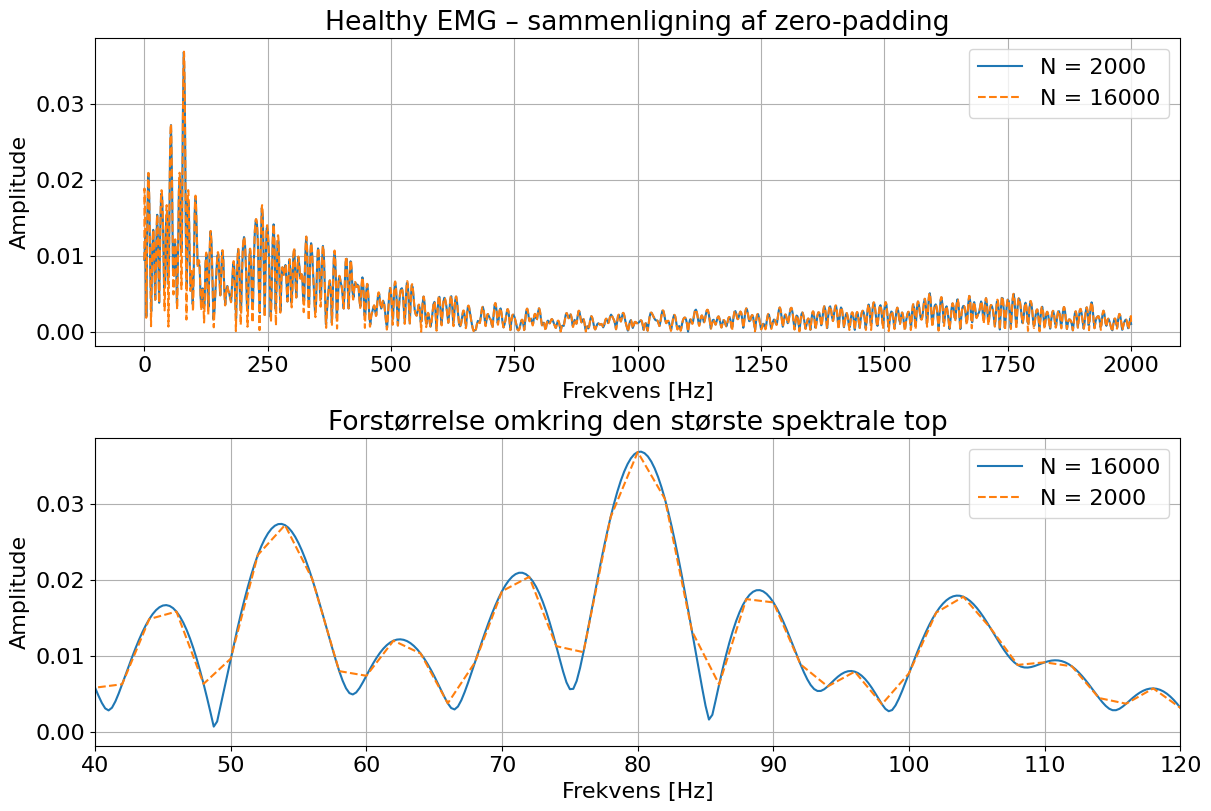

In [11]:

x = x_healthy

# Spektrum fra opgave 2
f_2000, A_2000 = amplitudespektrum(
    x, fs_healthy, N=2000
)

# Otte gange større FFT-længde
f_16000, A_16000 = amplitudespektrum(
    x, fs_healthy, N=16000
)

print(f"N = 2000:  Δf = {fs_healthy / 2000:.2f} Hz")
print(f"N = 16000: Δf = {fs_healthy / 16000:.2f} Hz")

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 8),
    constrained_layout=True
)

# Hele frekvensområdet
ax[0].plot(f_2000, A_2000, label="N = 2000")
ax[0].plot(f_16000, A_16000, linestyle="--", label="N = 16000")
ax[0].set_title("Healthy EMG – sammenligning af zero-padding")
ax[0].set_xlabel("Frekvens [Hz]")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

# Forstørret område omkring den største top
ax[1].plot(f_16000, A_16000, label="N = 16000")
ax[1].plot(f_2000, A_2000, linestyle="--", label="N = 2000")
ax[1].set_xlim(40, 120)
ax[1].set_title("Forstørrelse omkring den største spektrale top")
ax[1].set_xlabel("Frekvens [Hz]")
ax[1].set_ylabel("Amplitude")
ax[1].legend()

plt.show()

### Zero-padding til ottedobbelt FFT-længde

Ved frekvenstransformationen med \(N=16000\) tilføjes der derfor
15370 nuller efter signalet.

Frekvensafstanden ved \(N=2000\) var:

$$
\Delta f_{2000}
= \frac{4000}{2000}
= 2\,\mathrm{Hz}
$$

Ved \(N=16000\) bliver frekvensafstanden:

$$
\Delta f_{16000}
= \frac{4000}{16000}
= 0{,}25\,\mathrm{Hz}
$$

De to spektre har samme overordnede form og omtrent samme
amplituder, fordi de er beregnet ud fra de samme målte samples.
Spektret med \(N=16000\) fremstår dog mere glat og detaljeret,
fordi frekvensaksen indeholder otte gange så tætte punkter.

Den største spektrale top findes ved cirka 80 Hz i begge tilfælde.
Med \(N=2000\) placeres den ved 80.00 Hz, mens det tættere
frekvensgitter ved \(N=16000\) placerer maksimum ved cirka
80.25 - 80.50 Hz.

Zero-padding tilfører ikke ny information til signalet og forbedrer
ikke den egentlige evne til at adskille tætliggende frekvenser.
Det giver alene en tættere sampling af det eksisterende spektrum,
så det bliver lettere at aflæse og estimere placeringen af toppene.*

In [4]:
#Indlæs EKG-data
mat = loadmat("ECG_complex.mat")

#ravel() smaler EKG-målepunkterne i en endimensional array
ecg = mat["signal_EKG"].ravel()

#item() henter sample frekvensen et tal
fs_ecg = mat["f_sample"].item()


print("EKG-målepunkter:", len(ecg))
print(f"Sample frekvens for EKG: {fs_ecg} Hz")


EKG-målepunkter: 24650
Sample frekvens for EKG: 2000 Hz
